# Optimization 2: hyperparameter search with Optuna

Every model has settings you choose before training (tree depth, learning rate, and so on). Finding good values by hand is slow. This notebook searches for them automatically for **XGBoost**, using two algorithms so you can compare them:

- **Random search:** tries random combinations.
- **TPE (Bayesian optimization, Optuna's default):** learns from earlier trials which regions of the search space look promising and samples there more often.

Each trial trains an XGBoost model and scores it on the validation set. The best settings are then used to train a final model.

**Feasibility:** fully feasible, but time-consuming, because every trial trains a model. Use `TRAIN_ROWS` to search on a subsample and `N_TRIALS` to control the cost. The validation set is used both to search and to report the result, so the final score is slightly optimistic. Say so in your report. Run after the preprocessing notebook.

Install once if needed: `%pip install optuna xgboost`

## 1. Imports

In [1]:
# %pip install optuna xgboost matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import optuna
import xgboost as xgb
from sklearn.model_selection import train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Config

`TARGET` chooses what to optimize: `"multiclass"` (macro F1 over all classes, the harder problem and the one where tuning helps most) or `"binary"` (F1 for normal vs attack).

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

TARGET = "multiclass"       # "multiclass" or "binary"
N_TRIALS = 25               # trials per search algorithm
TRAIN_ROWS = 60000          # stratified subsample used during the search (None = all rows)
SEARCH_MAX_TREES = 400      # trees per trial (early stopping ends most trials sooner)
COMPARE_WITH_RANDOM = True  # also run a random search with the same number of trials

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 3b. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

## 4. Define the search

In [5]:
if TARGET == "multiclass":
    y_tr_full, y_va = ym_train, ym_val
    weights = np.array([cw_multi[i] for i in range(n_classes)])
    OBJ = dict(objective="multi:softprob", eval_metric="mlogloss")
else:
    y_tr_full, y_va = yb_train, yb_val
    weights = np.array([cw_bin[0], cw_bin[1]])
    OBJ = dict(objective="binary:logistic", eval_metric="logloss")


def score_fn(y_true, pred):
    return f1_score(y_true, pred, average="macro") if TARGET == "multiclass" else f1_score(y_true, pred)


if TRAIN_ROWS and TRAIN_ROWS < len(X_train):
    idx, _ = train_test_split(np.arange(len(X_train)), train_size=TRAIN_ROWS,
                              stratify=ym_train, random_state=SEED)
else:
    idx = np.arange(len(X_train))
X_search, y_search = X_train[idx], y_tr_full[idx]
w_search = weights[y_search]
print(f"target: {TARGET}   search rows: {len(idx):,}")


def fit_eval(params, max_trees=SEARCH_MAX_TREES):
    model = xgb.XGBClassifier(
        n_estimators=max_trees, early_stopping_rounds=20, tree_method="hist",
        n_jobs=-1, random_state=SEED, **OBJ, **params)
    model.fit(X_search, y_search, sample_weight=w_search, eval_set=[(X_val, y_va)], verbose=False)
    return score_fn(y_va, model.predict(X_val))


def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 12),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
    )
    return fit_eval(params)


t0 = time.time()
default_score = fit_eval({})
print(f"XGBoost default settings: score {default_score:.4f}  ({time.time() - t0:.0f}s for one trial)")

target: multiclass   search rows: 60,000
XGBoost default settings: score 0.6852  (2s for one trial)


## 5. Run the searches

In [6]:
def run_study(sampler, label):
    study = optuna.create_study(direction="maximize", sampler=sampler)
    t0 = time.time()
    study.optimize(objective, n_trials=N_TRIALS)
    print(f"{label}: best score {study.best_value:.4f} after {N_TRIALS} trials ({time.time() - t0:.0f}s)")
    return study


study_tpe = run_study(optuna.samplers.TPESampler(seed=SEED), "TPE (Bayesian)")
study_rand = run_study(optuna.samplers.RandomSampler(seed=SEED), "Random") if COMPARE_WITH_RANDOM else None

TPE (Bayesian): best score 0.7040 after 25 trials (248s)
Random: best score 0.6989 after 25 trials (190s)


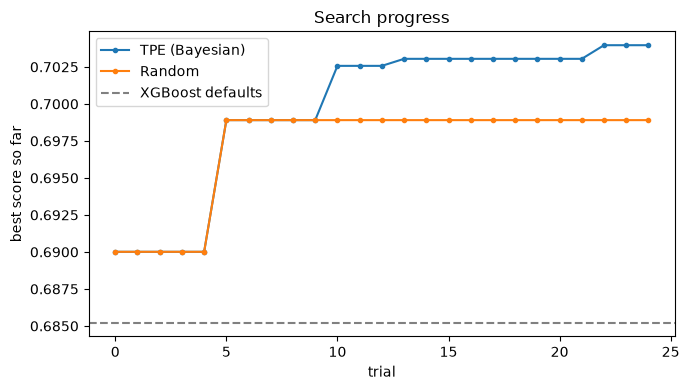

best parameters (TPE):
{
  "learning_rate": 0.027761095235012856,
  "max_depth": 8,
  "min_child_weight": 4,
  "subsample": 0.9926835017121253,
  "colsample_bytree": 0.6074961272481447,
  "reg_lambda": 0.03262610001716956,
  "reg_alpha": 0.004906657187407031,
  "gamma": 4.329860554267979
}


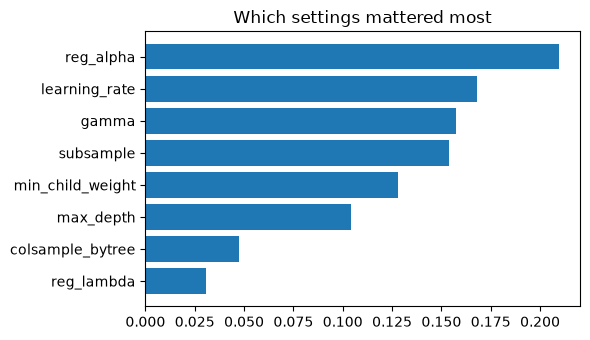

In [7]:
plt.figure(figsize=(7, 4))
for study, label in [(study_tpe, "TPE (Bayesian)"), (study_rand, "Random")]:
    if study is not None:
        vals = [t.value for t in study.trials]
        plt.plot(np.maximum.accumulate(vals), marker="o", markersize=3, label=label)
plt.axhline(default_score, color="grey", linestyle="--", label="XGBoost defaults")
plt.xlabel("trial"); plt.ylabel("best score so far")
plt.title("Search progress"); plt.legend(); plt.tight_layout(); plt.show()

print("best parameters (TPE):")
print(json.dumps(study_tpe.best_params, indent=2))

try:
    imp = optuna.importance.get_param_importances(study_tpe)
    plt.figure(figsize=(6, 3.5))
    plt.barh(list(imp)[::-1], list(imp.values())[::-1])
    plt.title("Which settings mattered most"); plt.tight_layout(); plt.show()
except Exception as e:
    print("parameter importance not available:", e)

## 6. Train the final model with the best settings

It uses all training rows and early stopping, and is evaluated with the same report as every other notebook.

final model: 998 trees in 49.5s
                precision    recall  f1-score   support

        Normal     0.9922    0.8572    0.9198     11200
           DoS     0.3162    0.7102    0.4376      2453
Reconnaissance     0.8278    0.8109    0.8193      2099
       Fuzzers     0.6743    0.8743    0.7614      3637
      Exploits     0.8626    0.4945    0.6286      6678
       Generic     0.9996    0.9815    0.9905      8000
         Other     0.2988    0.4261    0.3513      1002

      accuracy                         0.7929     35069
     macro avg     0.7102    0.7364    0.7012     35069
  weighted avg     0.8593    0.7929    0.8081     35069

macro F1:    0.7012
weighted F1: 0.8081


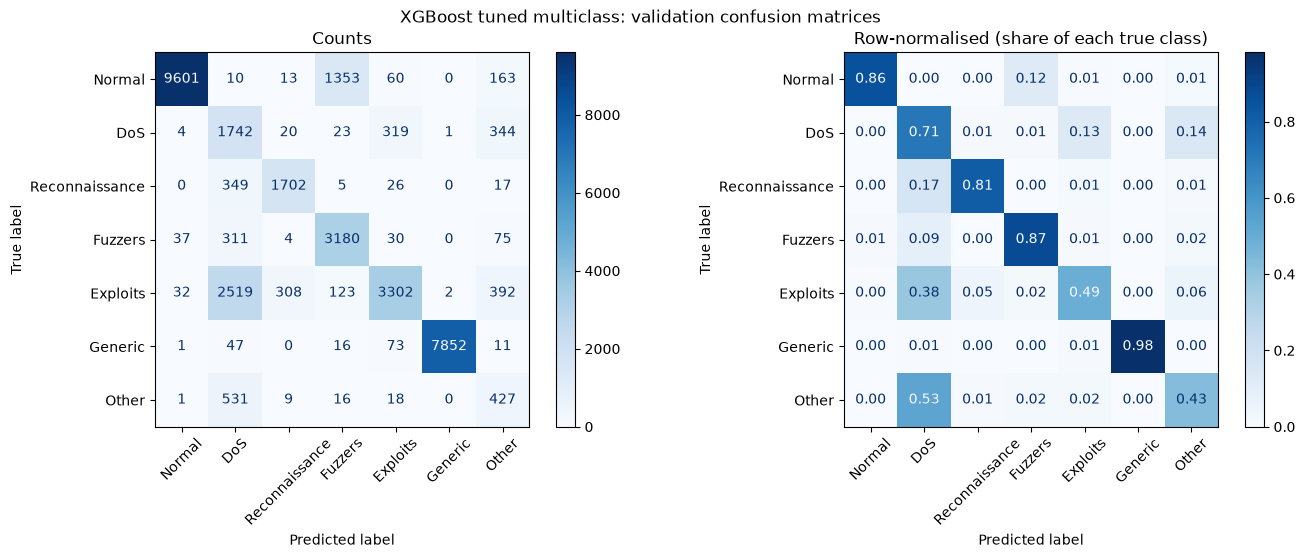

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,14.28,85.72
1,DoS,2453,99.84,71.02
2,Reconnaissance,2099,100.00,81.09
3,Fuzzers,3637,98.98,87.43
4,Exploits,6678,99.52,49.45
5,Generic,8000,99.99,98.15
6,Other,1002,99.90,42.61


In [8]:
best_params = study_tpe.best_params
final = xgb.XGBClassifier(
    n_estimators=1000, early_stopping_rounds=30, tree_method="hist",
    n_jobs=-1, random_state=SEED, **OBJ, **best_params)
w_full = weights[y_tr_full]
t0 = time.time()
final.fit(X_train, y_tr_full, sample_weight=w_full, eval_set=[(X_val, y_va)], verbose=False)
print(f"final model: {final.best_iteration + 1} trees in {time.time() - t0:.1f}s")

ms = ms_per_1000(final.predict, X_val)
if TARGET == "multiclass":
    row = report_multiclass(ym_val, final.predict(X_val), "XGBoost tuned multiclass", ms=ms)
else:
    proba = final.predict_proba(X_val)[:, 1]
    row = report_binary(yb_val, (proba >= 0.5).astype(int), "XGBoost tuned binary", score=proba, ms=ms)

## 7. Save and compare

In [9]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
final.save_model(mdir / f"xgb_tuned_{TARGET}.json")
(mdir / f"xgb_tuned_{TARGET}_params.json").write_text(json.dumps(best_params, indent=2))
pd.DataFrame([row]).to_csv(mdir / "xgbtuned_validation_summary.csv", index=False)
print("saved tuned model and parameters to", mdir)

saved tuned model and parameters to models


In [10]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,CNN binary,0.9757,0.9403,0.9577,0.0499,24.1
4,CNN multiclass (macro),0.7158,0.7336,0.7000,NaN,21.0
5,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
6,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
7,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
8,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
9,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
